In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import statsmodels.formula.api as smf

In [40]:
one_job_per_thread = pd.read_csv('./integral_parallel_measurements/measurements_thread_pool_1_partitions.csv')
one_job_per_thread = one_job_per_thread.drop(one_job_per_thread.index[-1])
three_jobs_per_thread = pd.read_csv('./integral_parallel_measurements/measurements_thread_pool_3_partitions.csv')
three_jobs_per_thread = three_jobs_per_thread.drop(three_jobs_per_thread.index[-1])
eight_jobs_per_thread = pd.read_csv('./integral_parallel_measurements/measurements_thread_pool_8_partitions.csv')
eight_jobs_per_thread = eight_jobs_per_thread.drop(eight_jobs_per_thread.index[-1])

one_job_per_thread['partitions'] = 1
three_jobs_per_thread['partitions'] = 3
eight_jobs_per_thread['partitions'] = 8

df = pd.concat([one_job_per_thread, three_jobs_per_thread, eight_jobs_per_thread])
df['threads_num'] = df["threads/func"]
df = df.drop("threads/func", axis=1)


## Function 1

We have decided to throw out measurements for 100 and 1000 number of threads as they are outliers.

In [41]:
pd.concat([one_job_per_thread.head(2), three_jobs_per_thread.tail(2), eight_jobs_per_thread.head(2)])

,threads/func,1,2,3,partitions
0,1,658.2,789.0,5.0,1
1,2,334.0,403.0,3.0,1
14,15,80.2,95.8,6.8,3
15,16,81.8,97.8,7.6,3
0,1,674.4,820.0,5.2,8
1,2,336.2,415.0,3.0,8


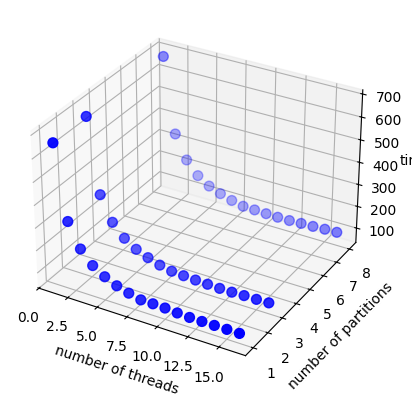

In [42]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

ax.scatter(df["threads_num"], df["partitions"], df["1"], c='blue', marker='o', s=50)

ax.set_xlabel("number of threads")
ax.set_ylabel("number of partitions")
ax.set_zlabel("time")

plt.show()

In [43]:
exec_time_model = smf.ols(formula='1 ~ threads_num + partitions', data=df).fit()
exec_time_model.summary()


/Users/vitya/Documents/acs/lab5-threadpool-integral-valihursyi_shtohryn_tarnavskyi/.env/lib/python3.11/site-packages/statsmodels/regression/linear_model.py:1782: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr/self.centered_tss


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              Intercept   R-squared:                        -inf
Model:                            OLS   Adj. R-squared:                   -inf
Method:                 Least Squares   F-statistic:                    -22.50
Date:                Wed, 19 Mar 2025   Prob (F-statistic):               1.00
Time:                        23:05:34   Log-Likelihood:                 1573.3
No. Observations:                  48   AIC:                            -3141.
Df Residuals:                      45   BIC:                            -3135.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       1.0000   5.25e-16   1.91e+15      0.000       1.000       1.000
threads_num  6.592e-17   4.56e-17      1.447      0.155   -2.58e-17    1.58e-16
partitions  -2.602e-17   7.13e-17     -0.365      0.717    -1.7e-16    1.18e-16
==============================================================================
Omnibus:                        3.882   Durbin-Watson:                   0.039
Prob(Omnibus):                  0.144   Jarque-Bera (JB):                1.767
Skew:                           0.022   Prob(JB):                        0.413
Kurtosis:                       2.061   Cond. No.                         26.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

P-value of the coefficient near number of partitions is very high, thus we consider it statistically insignificant for the following estimations. P-value of the t-test for coefficient near threads_num is also high, but setting size of test high enough we can accept null hypothesis.

Let $speedup_{obs}(n)=\frac{\text{execution on 1 thread}}{\text{execution on }n \text{ threads}}$ be observable speedup. Amdal's law states that $ speedup(n) = \frac{1}{(1-\alpha) + \frac{\alpha}{n}} $, where $\alpha$ is the part of the task that can be parallelized. Slightly rewriting equation:
$$
\frac{1}{speedup(n)} = (1-\alpha) + \frac{\alpha}{n} \\
\frac{1}{speedup(n)}-1 = \alpha(\frac{1}{n} - 1)
$$
We set $speedup(n)$ to be $speedup_{obs}(n)$. Now, we can estimate the parameter using OLS simple linear regression.


In [44]:
df = one_job_per_thread

baseline = df[(df["threads/func"] == 1) & (df["partitions"] == 1)]["1"].values[0]
df["speedup_obs"] = baseline/df["1"]

df["predicted"] = 1/df["speedup_obs"]-1
df["predictor"] = 1/df["threads/func"]-1

speedup_model = smf.ols(formula='predicted ~ predictor-1', data=df).fit()


print(f"alpha estimated to be:", round(speedup_model.params["predictor"], 3))

print(np.sum(df["predicted"]/df["predictor"])/len(df["predicted"]))

alpha estimated to be: 0.971
0.9124606835608431


We get an outstanding result of 97% paralellized looking at coefficient. However as we do not have intercept in this model, it makes it biased. Thus, this result should not be taken too seriously, as we used linear regression, and the relation we were looking for could have been not really linear in parameters. Also, estimating parameters by coefficients is bad practice, as coefficients depend on the scale of the variable.

I have tried more mathematically appropriate method 
$$
\alpha = \frac{\frac{1}{speedup(n)}-1}{\frac{1}{n} - 1}
$$
Took average of obtained value and got result of 0.91 which is more down to earth.

In [45]:
speedup_model.summary()

/Users/vitya/Documents/acs/lab5-threadpool-integral-valihursyi_shtohryn_tarnavskyi/.env/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:430: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=16 observations were given.
  return hypotest_fun_in(*args, **kwds)


<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:              predicted   R-squared (uncentered):                   1.000
Model:                            OLS   Adj. R-squared (uncentered):              1.000
Method:                 Least Squares   F-statistic:                          4.499e+04
Date:                Wed, 19 Mar 2025   Prob (F-statistic):                    1.69e-27
Time:                        23:05:34   Log-Likelihood:                          44.946
No. Observations:                  16   AIC:                                     -87.89
Df Residuals:                      15   BIC:                                     -87.12
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
predictor      0.9709      0.005    212.107      0.000       0.961       0.981
==============================================================================
Omnibus:                        1.305   Durbin-Watson:                   0.143
Prob(Omnibus):                  0.521   Jarque-Bera (JB):                1.072
Skew:                           0.454   Prob(JB):                        0.585
Kurtosis:                       2.115   Cond. No.                         1.00
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Even though, p-value for the $\alpha$ is very small, so it is statistically significant. R-squared is 1, which means that model explains 100% of variance of data.